# Predicting Vehicle CO2 Emissions with Simple Linear Regression

**Dataset:** `my2026-fuel-consumption-ratings.csv` (613 vehicles, model year 2026)

**Goal:** predict CO2 emissions of a vehicle from one feature, and compare two features:

| Model | Input feature (X) | Target (y) |
|---|---|---|
| Engine model | `Engine size (L)` | `CO2 emissions (g/km)` |
| Fuel model | `Combined (L/100 km)` | `CO2 emissions (g/km)` |

**Steps:**

1. Load the data
2. Understand the data
3. Explore the data with plots and correlation
4. Split the data into training and test sets
5. Train the models
6. Plot the fitted lines on the training data
7. Evaluate the models on the test data
8. Conclusions

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

%matplotlib inline
os.makedirs("images", exist_ok=True)   # folder for saved charts

In [2]:
df = pd.read_csv("my2026-fuel-consumption-ratings.csv")

print(df.shape)
df.sample(5, random_state=1)

(613, 15)


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
402,2026,Mazda,CX-90 4WD (High Power),Sport utility vehicle: Standard,3.3,6,AS8,Z,10.3,8.5,9.5,30,222,5,5
599,2026,Volkswagen,Golf GTI,Compact,2.0,4,AM7,X,9.9,7.4,8.8,32,205,5,4
107,2026,Chevrolet,Blazer AWD,Sport utility vehicle: Small,2.0,4,A9,X,10.8,8.7,9.9,29,232,5,6
472,2026,MINI,JCW 3 Door,Subcompact,2.0,4,AM7,Z,8.8,6.4,7.7,37,179,6,7
592,2026,Toyota,Tundra 4WD (3-mode),Pickup truck: Standard,3.4,6,AS10,X,13.5,10.6,12.2,23,287,4,4


- `pd.read_csv` reads the CSV file into a table (DataFrame) called `df`.
- `df.shape` shows the number of rows and columns: **613 vehicles** and **15 columns**.
- `df.sample(5)` shows 5 random rows to check the data was loaded correctly.

The original column names are kept. Because they contain spaces and parentheses (for example `Engine size (L)`),
columns are always accessed with square brackets: `df['Engine size (L)']`.

## 2. Understand the data

In [3]:
print(df.columns.tolist())

['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']


In [4]:
df.isnull().sum()

,0
Model year,0
Make,0
Model,0
Vehicle class,0
Engine size (L),0
Cylinders,0
Transmission,0
Fuel type,0
City (L/100 km),0
Highway (L/100 km),0


`isnull().sum()` counts empty cells in each column. All values are **0**, so the data is complete.

In [5]:
df.describe()

,Model year,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
count,613.0,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000
mean,2026.0,2.983687,5.399674,12.022023,9.285808,10.792496,28.238173,253.101142,4.433931,4.985318
std,0.0,1.227941,1.831586,3.452685,2.266554,2.856847,8.459363,66.375956,1.327545,1.356940
min,2026.0,1.200000,3.000000,4.400000,4.400000,4.400000,14.000000,104.000000,1.000000,1.000000
25%,2026.0,2.000000,4.000000,9.600000,7.500000,8.700000,22.000000,203.000000,4.000000,4.000000
50%,2026.0,2.700000,4.000000,12.000000,9.000000,10.700000,26.000000,252.000000,4.000000,5.000000
75%,2026.0,3.500000,6.000000,14.300000,10.700000,12.600000,32.000000,296.000000,5.000000,6.000000
max,2026.0,6.700000,12.000000,23.500000,16.600000,19.700000,64.000000,460.000000,8.000000,7.000000


`describe()` shows for each numeric column:

- **count**: number of values
- **mean**: average
- **std**: standard deviation (how spread out the values are)
- **min / max**: smallest and largest value
- **25% / 50% / 75%**: quartiles (50% is the median)

**Observation:** `Model year` has **std = 0** because every vehicle is a 2026 model.
A column that never changes cannot help predict anything, so it is not used.

## 3. Explore the data

### 3.1 Select features

Keep four columns that are likely related to CO2 emissions.

In [6]:
cdf = df[['Engine size (L)', 'Cylinders', 'Combined (L/100 km)', 'CO2 emissions (g/km)']]
cdf.sample(9, random_state=1)

,Engine size (L),Cylinders,Combined (L/100 km),CO2 emissions (g/km)
402,3.3,6,9.5,222
599,2.0,4,8.8,205
107,2.0,4,9.9,232
472,2.0,4,7.7,179
592,3.4,6,12.2,287
383,2.4,4,8.6,199
173,2.3,4,13.2,309
512,4.0,8,12.5,295
435,4.0,8,14.5,347


### 3.2 Histograms

A histogram shows how often each range of values occurs. The x-axis is the value; the y-axis is the number of vehicles.

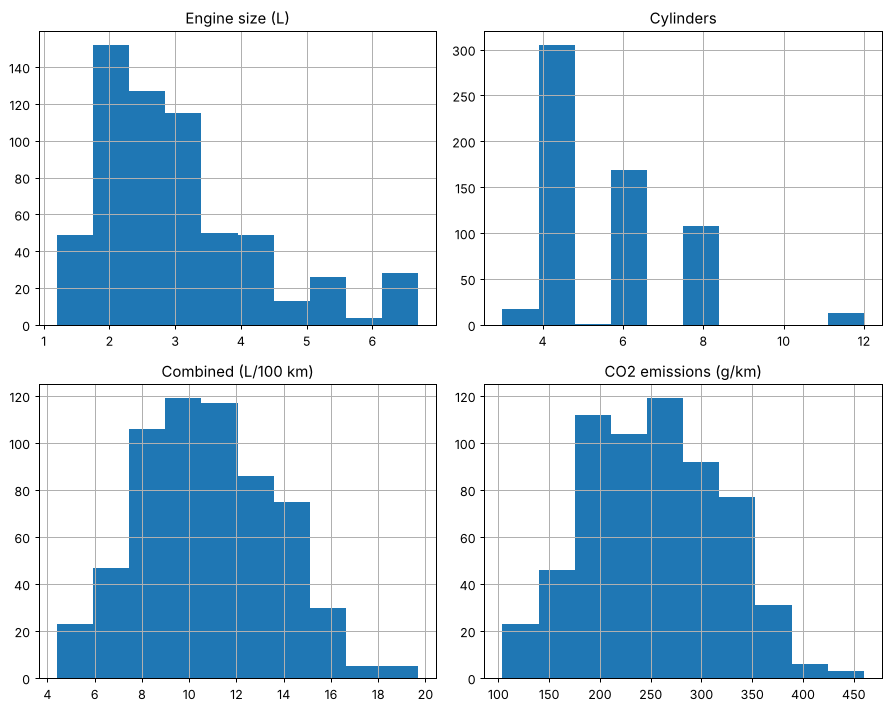

In [7]:
cdf.hist(figsize=(10, 8))
plt.tight_layout()
plt.savefig("images/01_histograms.png", dpi=120)
plt.show()

- **Engine size:** most engines are between 1.5 and 3.5 L, with the highest bar around 2.0 L. A few large engines (5 to 6.7 L) make a tail to the right (right-skewed).
- **Cylinders:** 4 cylinders is the most common (about 300 vehicles), then 6 and 8. There are gaps between the bars because cylinders are whole numbers (discrete data).
- **Combined fuel consumption:** most vehicles use 7.5 to 15 L/100 km, with the peak around 10 to 12.
- **CO2 emissions:** most vehicles emit 175 to 350 g/km, with the peak around 250.

The fuel consumption and CO2 histograms have a **very similar shape**, a hint that these two columns are strongly related.
A histogram does not show the relationship between two columns directly; scatter plots do.

### 3.3 Scatter plots

In a scatter plot each dot is one vehicle. If the dots fall close to a straight line, the relationship is **linear**
and linear regression is a good fit.

`plt.subplots(1, 3)` creates one figure with 1 row and 3 plots. `sharey=True` gives all three the same y-axis so they are easy to compare.

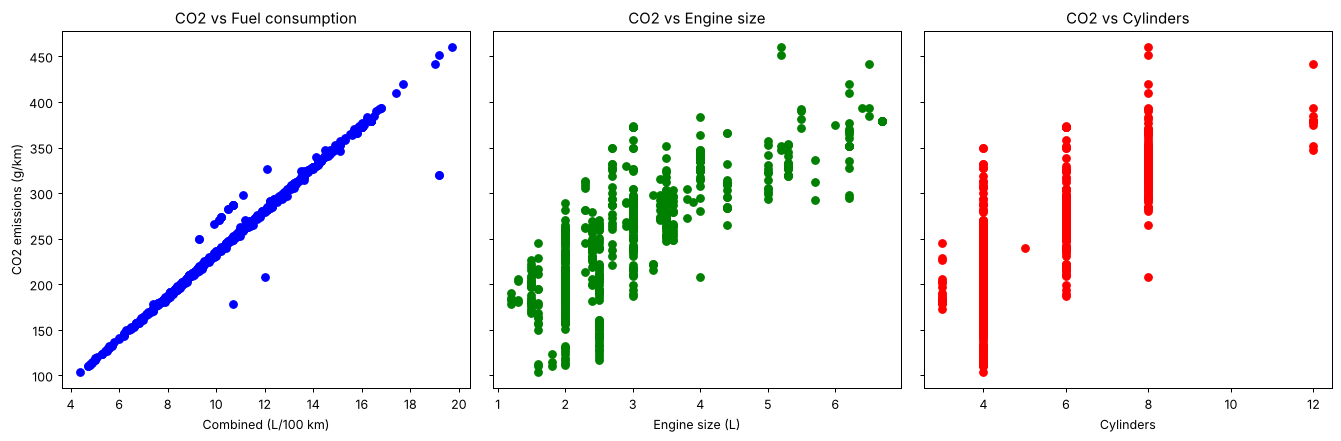

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

ax[0].scatter(cdf['Combined (L/100 km)'], cdf['CO2 emissions (g/km)'], color='blue')
ax[0].set_title('CO2 vs Fuel consumption')
ax[0].set_xlabel('Combined (L/100 km)')
ax[0].set_ylabel('CO2 emissions (g/km)')

ax[1].scatter(cdf['Engine size (L)'], cdf['CO2 emissions (g/km)'], color='green')
ax[1].set_title('CO2 vs Engine size')
ax[1].set_xlabel('Engine size (L)')

ax[2].scatter(cdf['Cylinders'], cdf['CO2 emissions (g/km)'], color='red')
ax[2].set_title('CO2 vs Cylinders')
ax[2].set_xlabel('Cylinders')

plt.tight_layout()
plt.savefig("images/02_scatter_comparison.png", dpi=120)
plt.show()

- **Fuel consumption (blue):** the dots form almost a perfect straight line. CO2 is produced by burning fuel, so each litre burned gives roughly the same amount of CO2.
  A few dots sit away from the line: the vehicles above it are **diesel** (`Fuel type = D`) and the ones below it are **E85 ethanol** (`Fuel type = E`).
- **Engine size (green):** CO2 rises with engine size, but the dots form a wide cloud. For example, 2 L engines range from about 110 to 290 g/km.
- **Cylinders (red):** the dots stack in vertical columns (whole numbers). The trend is upward, but the spread inside each column is large and the columns overlap.
  4-cylinder cars range from about 100 to 350 g/km, and some 12-cylinder cars emit less than some 8-cylinder cars.

### 3.4 Correlation

The correlation coefficient is a number between **-1 and 1**:

- close to **1**: strong positive linear relationship
- close to **0**: no linear relationship
- close to **-1**: strong negative linear relationship

In [9]:
print(cdf.corr()['CO2 emissions (g/km)'])

Engine size (L)         0.771535
Cylinders               0.764154
Combined (L/100 km)     0.987782
CO2 emissions (g/km)    1.000000
Name: CO2 emissions (g/km), dtype: float64


| Feature | Correlation with CO2 |
|---|---|
| Combined (L/100 km) | **0.988** |
| Engine size (L) | 0.772 |
| Cylinders | 0.764 |

The numbers confirm the plots: **fuel consumption** has the strongest linear relationship with CO2.

**Why also build an engine size model?**

1. Comparing a strong feature with a weaker one shows what a good model and an average model look like in the evaluation metrics.
2. CO2 in this file is essentially calculated from fuel consumption, so predicting one from the other is almost circular.
   Engine size is known from the spec sheet before any testing, which makes it a more realistic prediction question.

## 4. Split the data into training and test sets

A model must be tested on data it has **never seen**, like an exam with questions that were not solved in class.

- **Training set (80%)**: the model learns from these vehicles.
- **Test set (20%)**: kept aside and used only for the final evaluation.

Code notes:

- `X` is the input (what we know); `y` is the target (what we want to predict).
- `to_numpy()` converts a pandas column (Series) into a NumPy array. This is needed because `reshape` (used in the next step) is a NumPy method.
- `test_size=0.2`: 20% of the rows go to the test set.
- `random_state=42`: the split is random, but a fixed seed makes it **repeatable**. Both splits use the same seed and the same number of rows,
  so both models are trained and tested on **exactly the same vehicles**. That makes the comparison fair.
- `train_test_split` always receives the **full** data (`X`, `y`), never a part that was already split.

In [10]:
y = cdf['CO2 emissions (g/km)'].to_numpy()

X_eng  = cdf['Engine size (L)'].to_numpy()
X_fuel = cdf['Combined (L/100 km)'].to_numpy()

X_eng_train,  X_eng_test,  y_train, y_test = train_test_split(X_eng,  y, test_size=0.2, random_state=42)
X_fuel_train, X_fuel_test, y_train, y_test = train_test_split(X_fuel, y, test_size=0.2, random_state=42)

print("Train:", X_eng_train.shape)
print("Test: ", X_eng_test.shape)

Train: (490,)
Test:  (123,)


**490 vehicles** for training and **123** for testing (490 + 123 = 613).

`y_test` contains only CO2 values (the correct answers for the 123 test vehicles). It is the same for both models,
because both splits selected the same vehicles. The second split simply overwrites `y_train` and `y_test` with identical values.

## 5. Train the models

`LinearRegression()` creates an empty model. `.fit(X, y)` trains it: it finds the straight line that best fits the training data:

$$\text{CO2} = \text{coef} \times X + \text{intercept}$$

**Why `reshape(-1, 1)`?** scikit-learn expects a 2D table as input: **rows = vehicles, columns = features**.
Our arrays are 1D with shape `(490,)`. `reshape(-1, 1)` changes them to `(490, 1)`: 490 rows and 1 column.
The `-1` means "calculate the number of rows automatically".
(`reshape(1, -1)` would be wrong: it means 1 vehicle with 490 features.)

**Why `coef_[0]`?** `coef_` is an array with one coefficient per feature. We have one feature, so `[0]` takes the first (and only) value.
`intercept_` is always a single number, so it needs no index.

In [11]:
model_eng = LinearRegression()
model_eng.fit(X_eng_train.reshape(-1, 1), y_train)

model_fuel = LinearRegression()
model_fuel.fit(X_fuel_train.reshape(-1, 1), y_train)

print('Model eng coef:', model_eng.coef_[0], 'Model eng intercept:', model_eng.intercept_)
print('Model fuel coef:', model_fuel.coef_[0], 'Model fuel intercept:', model_fuel.intercept_)

Model eng coef: 41.27671069880367 Model eng intercept: 130.46369964006288
Model fuel coef: 23.107449015184198 Model fuel intercept: 4.059974936023963


**Coefficients:**

- **Engine model:** each extra litre of engine size adds about **41 g/km** of CO2.
- **Fuel model:** each extra 1 L/100 km of fuel consumption adds about **23 g/km** of CO2.

**Intercepts:**

- Fuel model: about **4**, very close to zero. This makes sense: a car that burns zero fuel produces zero CO2.
- Engine model: about **130**, which would mean a "0-litre engine" emits 130 g/km. This has no physical meaning;
  it only shows the line should not be used outside the range of the data.

## 6. Plot the fitted lines on the training data

Blue dots are the real training vehicles. The red line is the model: for each X it calculates
$\text{coef} \times X + \text{intercept}$.

Only the **training** data is plotted here, because this is the data the model learned from.

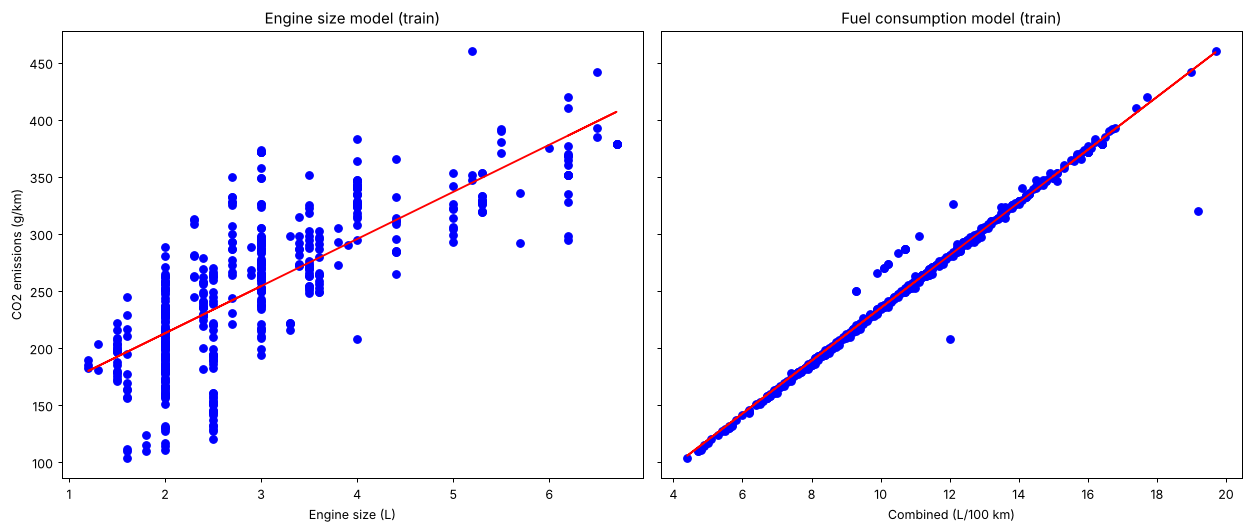

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

ax[0].scatter(X_eng_train, y_train, color='blue')
ax[0].plot(X_eng_train, model_eng.coef_[0] * X_eng_train + model_eng.intercept_, color='red')
ax[0].set_title('Engine size model (train)')
ax[0].set_xlabel('Engine size (L)')
ax[0].set_ylabel('CO2 emissions (g/km)')

ax[1].scatter(X_fuel_train, y_train, color='blue')
ax[1].plot(X_fuel_train, model_fuel.coef_[0] * X_fuel_train + model_fuel.intercept_, color='red')
ax[1].set_title('Fuel consumption model (train)')
ax[1].set_xlabel('Combined (L/100 km)')

plt.tight_layout()
plt.savefig("images/03_fitted_lines_train.png", dpi=120)
plt.show()

- **Engine model:** the line goes through the middle of the cloud and follows the general trend, but many points are far from it.
  For a 2 L engine the line predicts $41.28 \times 2 + 130.46 \approx 213$ g/km, while the real values are spread from about 110 to 290.
- **Fuel model:** the line passes almost exactly through the points. Only the few diesel and ethanol vehicles are away from it.

**Important:** each line must use the coefficient **and** intercept of its **own** model. Mixing them
(for example `model_eng.coef_` with `X_fuel_train`) gives no error message, but draws a wrong line.
Always look at the plot to check the result makes sense.

## 7. Evaluate the models on the test data

The real exam: `predict` estimates CO2 for the 123 test vehicles the models have never seen.
Then the predictions (`y_pred`) are compared with the true values (`y_test`).

| Metric | Meaning | Better |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the error, in g/km | Lower |
| **MSE** (Mean Squared Error) | Average of the squared errors; large errors count much more | Lower |
| **RMSE** (Root MSE) | Square root of MSE, back in g/km | Lower |
| **R²** | Share of the variation in CO2 the model explains (1 = perfect) | Higher |

In [13]:
y_pred_eng  = model_eng.predict(X_eng_test.reshape(-1, 1))
y_pred_fuel = model_fuel.predict(X_fuel_test.reshape(-1, 1))

print("----- Engine size model -----")
print("MAE :  %.2f" % mean_absolute_error(y_test, y_pred_eng))
print("MSE :  %.2f" % mean_squared_error(y_test, y_pred_eng))
print("RMSE:  %.2f" % np.sqrt(mean_squared_error(y_test, y_pred_eng)))
print("R2  :  %.3f" % r2_score(y_test, y_pred_eng))

print("----- Fuel consumption model -----")
print("MAE :  %.2f" % mean_absolute_error(y_test, y_pred_fuel))
print("MSE :  %.2f" % mean_squared_error(y_test, y_pred_fuel))
print("RMSE:  %.2f" % np.sqrt(mean_squared_error(y_test, y_pred_fuel)))
print("R2  :  %.3f" % r2_score(y_test, y_pred_fuel))

----- Engine size model -----
MAE :  29.75
MSE :  1601.21
RMSE:  40.02
R2  :  0.596
----- Fuel consumption model -----
MAE :  3.75
MSE :  201.03
RMSE:  14.18
R2  :  0.949


| Metric | Engine size model | Fuel consumption model |
|---|---|---|
| MAE | 29.75 | **3.75** |
| MSE | 1601.21 | **201.03** |
| RMSE | 40.02 | **14.18** |
| R² | 0.596 | **0.949** |

- **MAE:** the engine model is wrong by about **30 g/km** on average (about 12% of a typical 250 g/km car).
  The fuel model is wrong by only about **4 g/km** (about 1.5%).
- **R²:** engine size explains about **60%** of the differences in CO2; fuel consumption explains about **95%**.
- **MAE vs RMSE:** for the fuel model, RMSE is almost 4 times MAE. MSE and RMSE square each error before averaging,
  so a few very large errors count much more than many small ones. When RMSE is much bigger than MAE, the model is usually accurate
  but makes a few big mistakes. Here those are the diesel and E85 ethanol vehicles that sit away from the line.

## 8. Conclusions

1. **Fuel consumption is the best predictor of CO2** (R² ≈ 0.95, MAE ≈ 4 g/km).
2. **Engine size is related to CO2 but weaker** (R² ≈ 0.60, MAE ≈ 30 g/km). One straight line cannot capture all the differences.
3. **Cylinders** also has an upward trend, but with a large spread, so it is not a good feature for a simple linear model.
4. Even the best model makes its largest errors on **diesel** and **E85 ethanol** vehicles, because it only sees fuel consumption and not the fuel type.

### Next step

**Multiple linear regression**: a model that uses several features at the same time (for example fuel consumption **and** fuel type).